<a href="https://colab.research.google.com/github/RoqaiaWagih/DIP-Image-Compression-Benchmark/blob/main/notebooks/Dataset_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install pillow pandas matplotlib requests

In [4]:

from pathlib import Path

ROOT = Path("/content/DIP_Project")

folders = [
    "datasets/kodak",
    "datasets/tecnick",
    "datasets/clic_validation",
    "reports",
    "results"
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created!")


Project folders created!


In [5]:

import requests
from PIL import Image

kodak_folder = ROOT / "datasets/kodak"

base_url = "https://r0k.us/graphics/kodak/kodak/"

for i in range(1, 25):
    filename = f"kodim{i:02d}.png"
    path = kodak_folder / filename
    url = base_url + filename

    try:
        if not path.exists():
            response = requests.get(
                url,
                timeout=30
            )
            response.raise_for_status()
            path.write_bytes(response.content)

        with Image.open(path) as img:
            if img.format != "PNG":
                raise ValueError("Unexpected image format")
            img.verify()

        print("OK:", filename)

    except Exception as e:
        path.unlink(missing_ok=True)
        print("FAILED:", filename, str(e))

print(
    "Files downloaded:",
    len(list(kodak_folder.glob("*.png")))
)


OK: kodim01.png
OK: kodim02.png
OK: kodim03.png
OK: kodim04.png
OK: kodim05.png
OK: kodim06.png
OK: kodim07.png
OK: kodim08.png
OK: kodim09.png
OK: kodim10.png
OK: kodim11.png
OK: kodim12.png
OK: kodim13.png
OK: kodim14.png
OK: kodim15.png
OK: kodim16.png
OK: kodim17.png
OK: kodim18.png
OK: kodim19.png
OK: kodim20.png
OK: kodim21.png
OK: kodim22.png
OK: kodim23.png
OK: kodim24.png
Files downloaded: 24


Display an original image


Image dimensions: (768, 512)
Image color mode: RGB


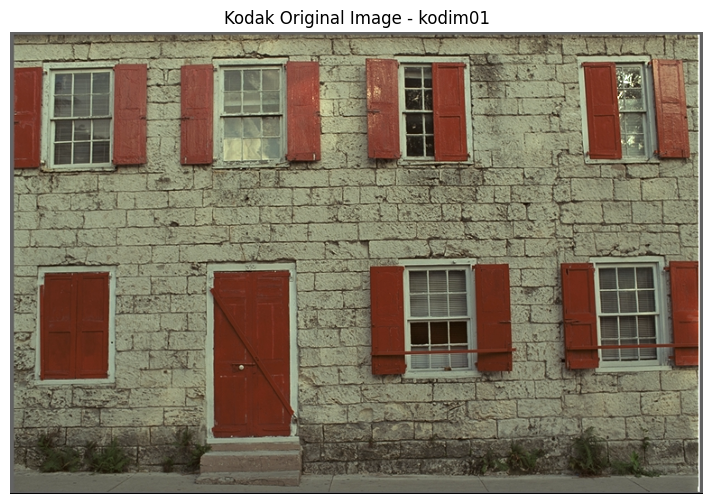

In [6]:

from PIL import Image
import matplotlib.pyplot as plt

image_path = ROOT / "datasets/kodak/kodim01.png"

with Image.open(image_path) as img:
    image = img.copy()

print("Image dimensions:", image.size)
print("Image color mode:", image.mode)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Kodak Original Image - kodim01")
plt.axis("off")
plt.show()




```
# Generate the dataset information CSV
```



In [7]:

import pandas as pd
from PIL import Image

records = []

dataset_folders = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC": ROOT / "datasets/clic_validation"
}

for dataset_name, folder in dataset_folders.items():
    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        try:
            with Image.open(path) as img:
                if img.format not in ("PNG", "TIFF", "BMP"):
                    continue

                records.append({
                    "Dataset": dataset_name,
                    "Filename": path.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Color Mode": img.mode,
                    "Size KB": round(
                        path.stat().st_size / 1024, 2
                    )
                })

        except Exception as error:
            print("Skipped:", path.name, error)

df = pd.DataFrame(records)

output = ROOT / "reports/dataset_information.csv"
df.to_csv(output, index=False)

display(df)

print("Number of images:", len(df))
print("Report saved:", output)


,Dataset,Filename,Width,Height,Format,Color Mode,Size KB
0,Kodak,kodim01.png,768,512,PNG,RGB,719.24
1,Kodak,kodim02.png,768,512,PNG,RGB,603.51
2,Kodak,kodim03.png,768,512,PNG,RGB,491.10
3,Kodak,kodim04.png,512,768,PNG,RGB,622.49
4,Kodak,kodim05.png,768,512,PNG,RGB,767.20
5,Kodak,kodim06.png,768,512,PNG,RGB,604.45
6,Kodak,kodim07.png,768,512,PNG,RGB,553.05
7,Kodak,kodim08.png,768,512,PNG,RGB,769.99
8,Kodak,kodim09.png,512,768,PNG,RGB,569.24
9,Kodak,kodim10.png,512,768,PNG,RGB,579.55


Number of images: 24
Report saved: /content/DIP_Project/reports/dataset_information.csv


In [8]:

from google.colab import files

files.download(str(output))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Verify your dataset**

In [9]:

from PIL import Image

valid = 0

for i in range(1, 25):
    filename = f"kodim{i:02d}.png"
    path = kodak_folder / filename

    try:
        with Image.open(path) as img:
            assert img.format == "PNG"
            assert img.mode == "RGB"
            img.verify()

        valid += 1
        print("PASS:", filename)

    except Exception as error:
        print("FAIL:", filename, error)

print(f"\nVerified: {valid}/24")

assert valid == 24, "Dataset incomplete!"


PASS: kodim01.png
PASS: kodim02.png
PASS: kodim03.png
PASS: kodim04.png
PASS: kodim05.png
PASS: kodim06.png
PASS: kodim07.png
PASS: kodim08.png
PASS: kodim09.png
PASS: kodim10.png
PASS: kodim11.png
PASS: kodim12.png
PASS: kodim13.png
PASS: kodim14.png
PASS: kodim15.png
PASS: kodim16.png
PASS: kodim17.png
PASS: kodim18.png
PASS: kodim19.png
PASS: kodim20.png
PASS: kodim21.png
PASS: kodim22.png
PASS: kodim23.png
PASS: kodim24.png

Verified: 24/24
